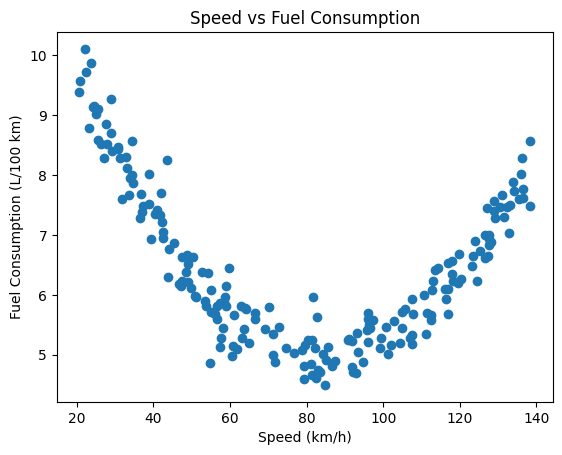

   Degree  Train RMSE  Test RMSE
0       1    1.214638   1.250836
1       2    0.331679   0.362448
2       3    0.326909   0.367680
3       4    0.326765   0.369838
4       5    0.324795   0.373634
5       6    0.324592   0.378586

Best Degree: 2
Best Test RMSE: 0.3624480869284379


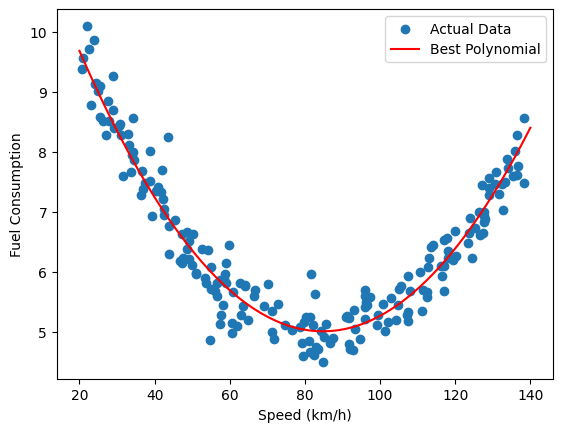


ANN Test RMSE: 0.40789460820190765

Prediction at 180 km/h
Polynomial Prediction: 15.102849972945736
ANN Prediction: 11.023965611529796

Conclusion:
Polynomial regression is generally more trustworthy here
because the underlying relationship is approximately quadratic.
180 km/h is outside the training range, so both predictions
are extrapolations and should be treated cautiously.


In [1]:

# Q2: Polynomial Regression and ANN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

# Generate dataset
np.random.seed(42)

speed = np.random.uniform(20, 140, 200)

fuel = 5 + 0.0011 * (speed - 85)**2 + np.random.normal(0, 0.35, 200)

X = speed.reshape(-1, 1)
y = fuel

# Scatter plot
plt.scatter(speed, fuel)
plt.xlabel("Speed (km/h)")
plt.ylabel("Fuel Consumption (L/100 km)")
plt.title("Speed vs Fuel Consumption")
plt.show()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
# PART A: Polynomial Regression
# -------------------------------

results = []

best_model = None
best_degree = None
best_rmse = float('inf')

for degree in range(1, 7):

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results.append([degree, train_rmse, test_rmse])

    if test_rmse < best_rmse:
        best_rmse = test_rmse
        best_degree = degree
        best_model = (poly, model)

# Display results
result_df = pd.DataFrame(
    results,
    columns=["Degree", "Train RMSE", "Test RMSE"]
)

print(result_df)

print("\nBest Degree:", best_degree)
print("Best Test RMSE:", best_rmse)

# Plot best polynomial curve
poly, model = best_model

x_curve = np.linspace(20, 140, 200).reshape(-1, 1)
y_curve = model.predict(poly.transform(x_curve))

plt.scatter(speed, fuel, label="Actual Data")
plt.plot(x_curve, y_curve, color="red", label="Best Polynomial")
plt.xlabel("Speed (km/h)")
plt.ylabel("Fuel Consumption")
plt.legend()
plt.show()

# -------------------------------
# PART B: ANN Regression
# -------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ann = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    max_iter=3000,
    random_state=42
)

ann.fit(X_train_scaled, y_train)

ann_pred = ann.predict(X_test_scaled)

ann_rmse = np.sqrt(mean_squared_error(y_test, ann_pred))

print("\nANN Test RMSE:", ann_rmse)

# Predict at 180 km/h
speed_180 = np.array([[180]])

poly_prediction = model.predict(poly.transform(speed_180))

ann_prediction = ann.predict(scaler.transform(speed_180))

print("\nPrediction at 180 km/h")

print("Polynomial Prediction:", poly_prediction[0])
print("ANN Prediction:", ann_prediction[0])

print("\nConclusion:")
print("Polynomial regression is generally more trustworthy here")
print("because the underlying relationship is approximately quadratic.")
print("180 km/h is outside the training range, so both predictions")
print("are extrapolations and should be treated cautiously.")
